In [2]:
import re
import string
import pandas as pd
import numpy as np
import time
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.feature_extraction.text import CountVectorizer


In [3]:
data = pd.read_csv("Mental Distress Dataset.csv")

Data Understanding

In [4]:
data.shape

(10100, 2)

In [5]:
data.head()

,text,label
0,"I have been (passively at best, actively at wo...",Suicidal
1,Idk when or how but soon. I will likely hang m...,Suicidal
2,I used to say that I would not commit suicide ...,Suicidal
3,Just so I can work minimum wage for 40 years w...,Suicidal
4,"for a little while, i did everything right. i ...",Suicidal


In [6]:
data.tail()

,text,label
10095,Apparently Taylor Swift likes Shakespeare. She...,Others
10096,The demon king slowly popping up in the backgr...,Others
10097,I like how soulless and fake they look when th...,Others
10098,"At first, I didn't know what to write, but now...",Others
10099,This is the end of the dataset. It is good tha...,Others


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10100 entries, 0 to 10099
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10098 non-null  object
 1   label   10100 non-null  object
dtypes: object(2)
memory usage: 157.9+ KB


In [8]:
# Check for missing values
print(data.isnull().sum())

text     2
label    0
dtype: int64


In [9]:
# Check where text is missing
missing_text = data[data['text'].isnull()]
print(missing_text)

     text      label
1767  NaN   Suicidal
6994  NaN  Depressed


In [10]:
# Drop Missing Text Records

print(f"Dataset shape before dropping: {data.shape}")
data = data.dropna(subset=['text'])
print(f"Dataset shape after dropping: {data.shape}")

Dataset shape before dropping: (10100, 2)
Dataset shape after dropping: (10098, 2)


In [11]:
# Checking Duplicates
print(f"Duplicates: {data['text'].duplicated().sum()}")

Duplicates: 48


In [12]:
# DROP DUPLICATES — KEEP FIRST

print(f"Before dropping duplicates: {data.shape}")
data = data.drop_duplicates(subset=['text'], keep='first').reset_index(drop=True)
print(f"After dropping duplicates: {data.shape}")
print(f"Duplicates removed: {10098 - len(data)}")

Before dropping duplicates: (10098, 2)
After dropping duplicates: (10050, 2)
Duplicates removed: 48


In [13]:
data.shape

(10050, 2)

Class Distribution

In [14]:
# Checking the count of target variable
class_distribution = data['label'].value_counts()
print(class_distribution)

label
Suicidal      2170
Depressed     2047
Anxious       2038
Frustrated    2021
Others        1774
Name: count, dtype: int64


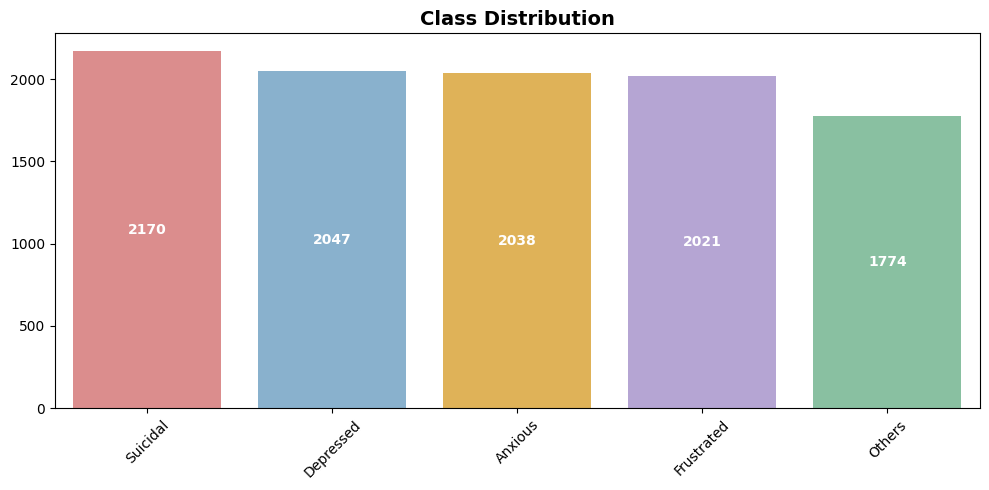

In [15]:
# Define consistent color palette
category_colors = {
    'Suicidal': '#E88080',
    'Depressed': '#7EB3D8',
    'Anxious': '#F5B942',
    'Frustrated': '#B39DDB',
    'Others': '#80C9A0'
}

# Plot
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values,
    hue=class_distribution.index,
    palette=category_colors,
    legend=False
)

# Add labels inside bars
for container in ax.containers:
    ax.bar_label(
        container,
        label_type='center',
        color='white',
        fontweight='bold'
    )

plt.title('Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.xticks(
    ticks=range(len(class_distribution.index)),
    labels=class_distribution.index,
    rotation=45
)
plt.tight_layout()
plt.show()

 Text Length Analysis

In [16]:
# Calculate word count
data['word_count'] = data['text'].apply(lambda x: len(str(x).split()))

# Display basic statistics
print("Word Count Statistics:")
print(data['word_count'].describe())

Word Count Statistics:
count    10050.000000
mean       117.006269
std        144.287881
min          3.000000
25%         34.000000
50%         70.000000
75%        146.000000
max       2599.000000
Name: word_count, dtype: float64


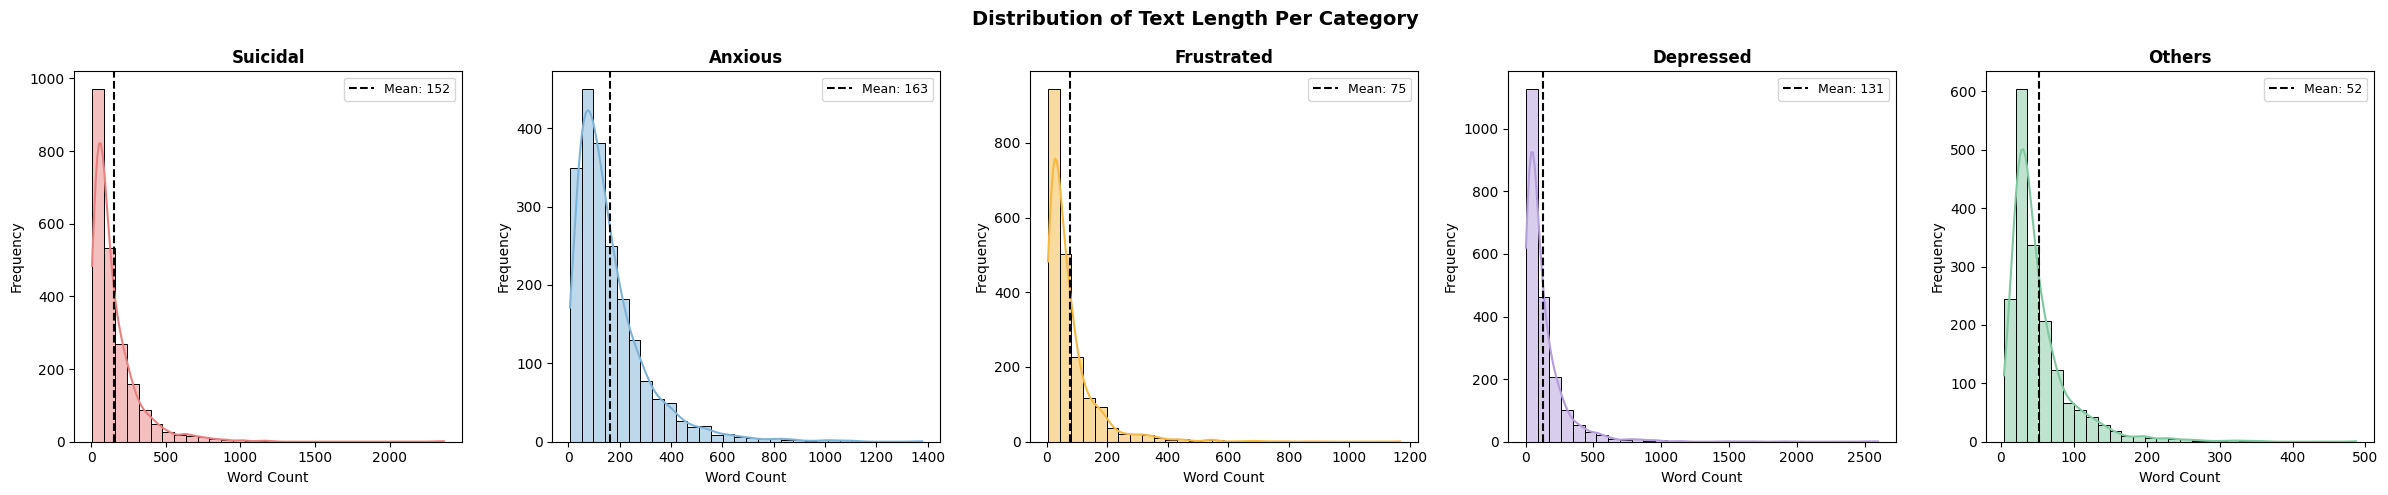

In [17]:
# Distribution of word count per category
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

categories = data['label'].unique()

for i, (category, ax) in enumerate(zip(categories, axes)):
    cat_data = data[data['label'] == category]['word_count']

    sns.histplot(cat_data, bins=30, kde=True,
                 color=list(category_colors.values())[i],
                 ax=ax)

    ax.set_title(f'{category}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Word Count')
    ax.set_ylabel('Frequency')
    ax.axvline(cat_data.mean(), color='black', linestyle='--',
               linewidth=1.5, label=f'Mean: {cat_data.mean():.0f}')
    ax.legend(fontsize=9)

plt.suptitle('Distribution of Text Length Per Category',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

 Most Frequent Words Before Preprocessing

In [18]:
# Clean text slightly for counting (lowercase and remove punctuation)
def basic_clean(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

# Combine all text
all_text = ' '.join(data['text'].dropna().apply(basic_clean).values)

# Count words
word_counts = Counter(all_text.split())

# Get top 10 most frequent words
top_words = pd.DataFrame(word_counts.most_common(10),
                          columns=['Word', 'Count'])

print(top_words)

   Word  Count
0     i  69674
1    to  36623
2   and  35334
3   the  28312
4     a  25065
5    my  23207
6    it  17785
7    of  17741
8  that  13925
9    is  13709


In [19]:
# TOP BIGRAMS BEFORE PREPROCESSING
# Extract Bigrams using Sklearn
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=10,
    stop_words=None  # no stopword removal — before preprocessing
)

# Fit and transform
X_bigram = bigram_vectorizer.fit_transform(data['text'].dropna())

# Get bigram counts
bigram_counts = X_bigram.toarray().sum(axis=0)
bigram_features = bigram_vectorizer.get_feature_names_out()

# Create dataframe
bigram_df = pd.DataFrame({
    'Bigram': bigram_features,
    'Count': bigram_counts
}).sort_values('Count', ascending=False)

print("Top 10 Bigrams Before Preprocessing:")
print(bigram_df)

Top 10 Bigrams Before Preprocessing:
      Bigram  Count
0     do not   4006
9    want to   3284
7      to be   2614
3     in the   2454
2      in my   2143
4      it is   1857
5      of my   1846
6     of the   1822
1  feel like   1704
8      to do   1654


In [20]:
# TOP TRIGRAMS BEFORE PREPROCESSING
# Extract Trigrams using Sklearn
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    max_features=10,
    stop_words=None  # no stopword removal — before preprocessing
)

# Fit and transform
X_trigram = trigram_vectorizer.fit_transform(data['text'].dropna())

# Get bigram counts
trigram_counts = X_trigram.toarray().sum(axis=0)
trigram_features = trigram_vectorizer.get_feature_names_out()

# Create dataframe
trigram_df = pd.DataFrame({
    'Bigram': trigram_features,
    'Count': trigram_counts
}).sort_values('Count', ascending=False)

print("Top 10 Trigrams Before Preprocessing:")
print(trigram_df)

Top 10 Trigrams Before Preprocessing:
         Bigram  Count
2   do not know    907
3   do not want    840
6   not want to    779
5  just want to    530
8   want to die    432
7    want to be    417
9    what to do    413
1   do not have    380
0    and do not    365
4    in my life    342


Data Preprocessing

In [21]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [22]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# PREPROCESSING FUNCTION

def preprocess_text(text):
    # Lowercase
    text = text.lower()

    # Handle contractions
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'d", " would", text)
    text = re.sub(r"'s", "", text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenise remove stopwords and lemmatise
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(token)
              for token in tokens
              if token not in stop_words
              and len(token) > 2]
    return ' '.join(tokens)

# Apply preprocessing
data['clean_text'] = data['text'].apply(preprocess_text)
print("Preprocessing complete!")
print(f"Dataset shape: {data.shape}")

# VERIFY
for i in range(3):
    print(f"\nOriginal: {data['text'].iloc[i]}")
    print(f"Cleaned:  {data['clean_text'].iloc[i]}")

Preprocessing complete!
Dataset shape: (10050, 4)

Original: I have been (passively at best, actively at worst) suicidal for more years (14+) than I have not been at this point. It feels like a cancer that I just cannot cut out, no matter what meds I take or what positive life changes I make. When I go to bed at night or take depression naps I cannot help but think of how nice it would be if I died in my sleep. I beg the universe for it sometimes. Especially with the trajectory of the world.And if I am not supposed to die then I wish that life could just pause for a few seconds. I am struggling to breathe, and its maddening not having adequate space to even attempt to work through these awful feelings. How do I tell my job, friends, family that my daily performance is suffering because I wish I was dead? How do I provide for myself if I am in long-term treatment? Rent does not go away. Responsibilities will pile up. I am so worried that if I acknowledge how bad things are and try to se

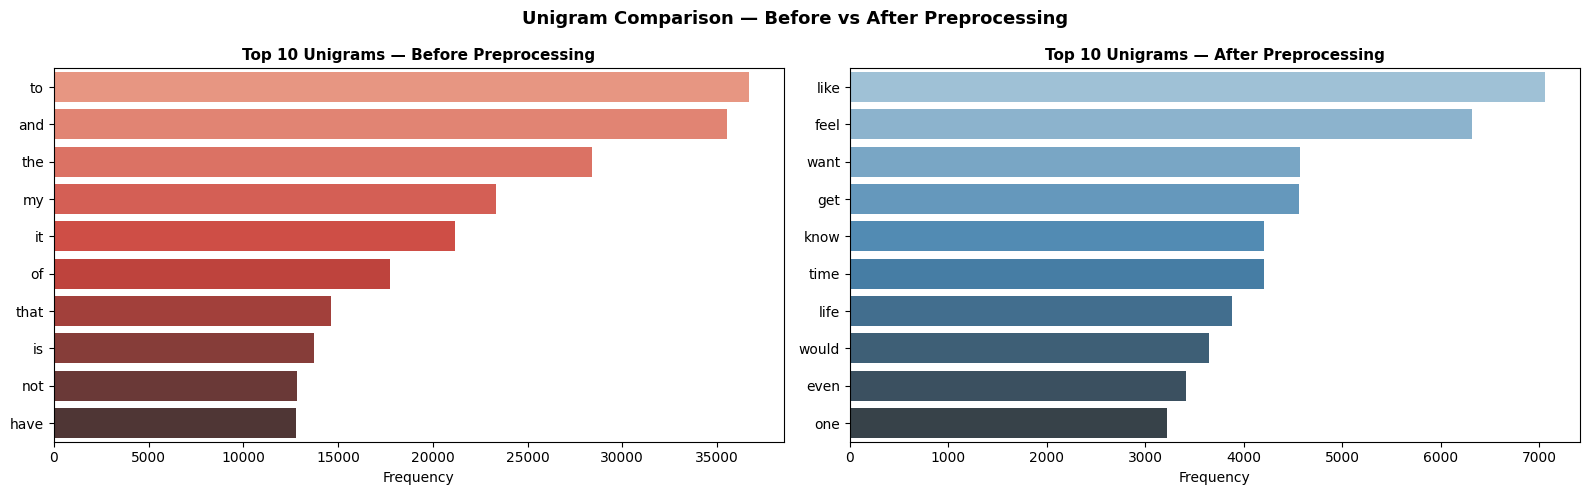

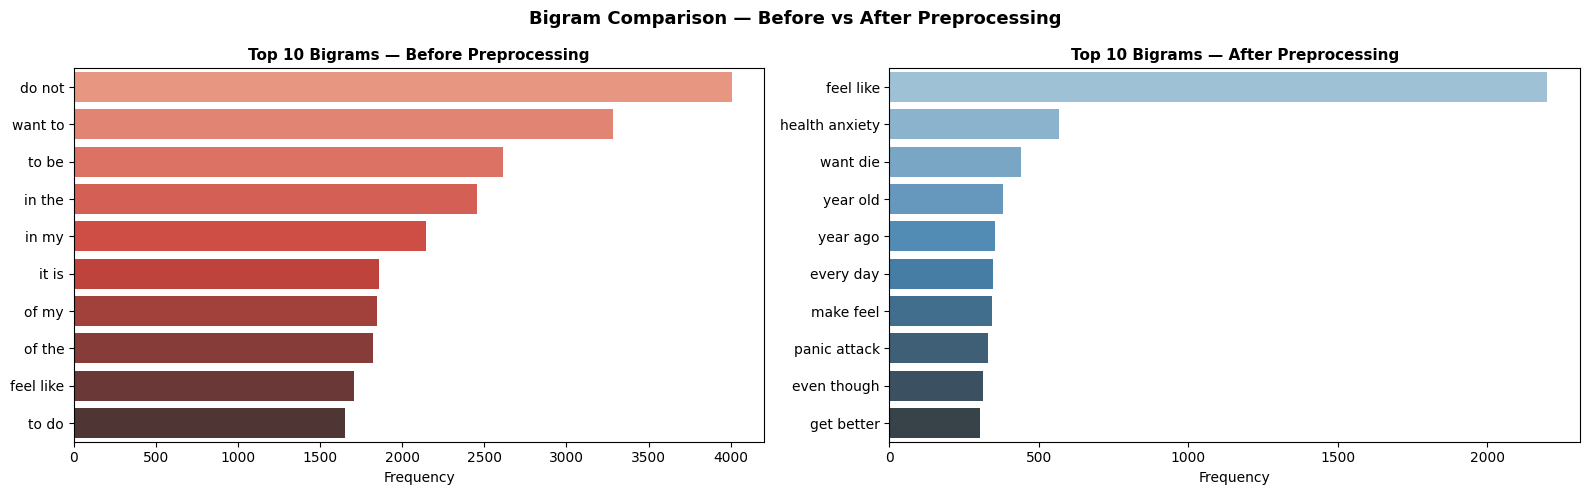

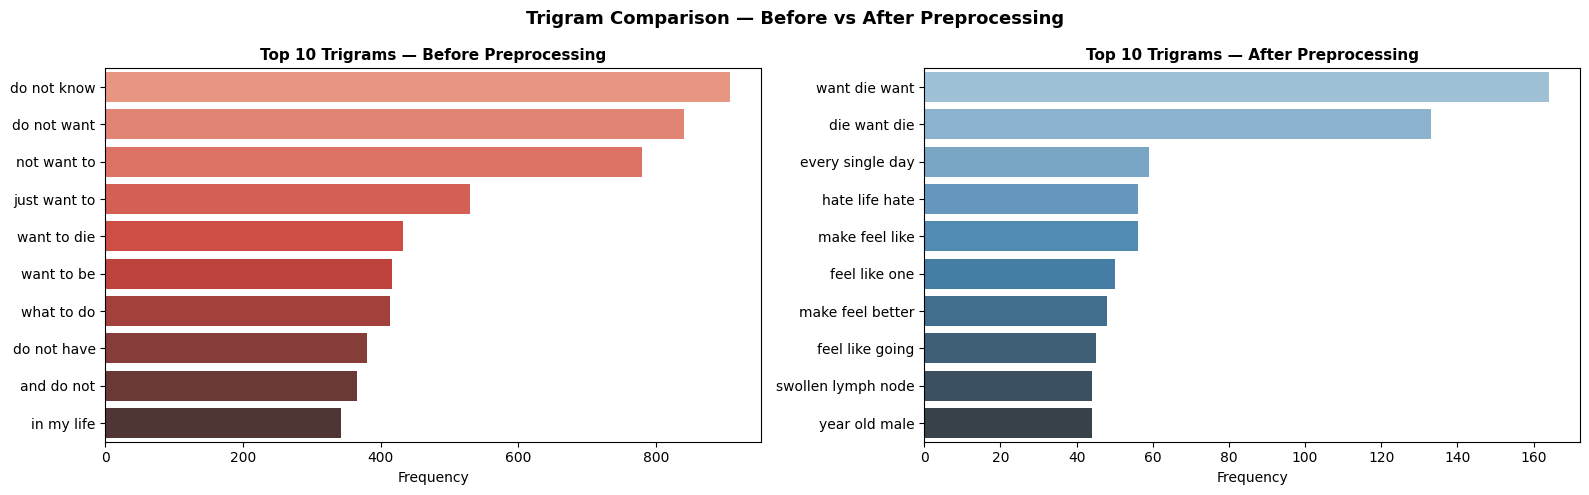

In [23]:
# TOP 10 WORDS BEFORE AND AFTER PREPROCESSING
# UNIGRAM, BIGRAM AND TRIGRAM
def plot_ngram(ax, data_col, ngram, min_df, title, color):
    cv = CountVectorizer(ngram_range=ngram, min_df=min_df)
    X = cv.fit_transform(data_col.dropna())
    freq = pd.DataFrame({
        'Term': cv.get_feature_names_out(),
        'Count': np.asarray(X.sum(axis=0)).flatten()
    }).sort_values('Count', ascending=False).head(10)

    sns.barplot(x='Count', y='Term', data=freq,
                hue='Term', palette=color,
                legend=False, ax=ax)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Frequency')
    ax.set_ylabel('')


# UNIGRAM — BEFORE AND AFTER
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_ngram(axes[0], data['text'], (1,1), 1,
           'Top 10 Unigrams — Before Preprocessing', 'Reds_d')
plot_ngram(axes[1], data['clean_text'], (1,1), 5,
           'Top 10 Unigrams — After Preprocessing', 'Blues_d')
plt.suptitle('Unigram Comparison — Before vs After Preprocessing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# BIGRAM — BEFORE AND AFTER
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_ngram(axes[0], data['text'], (2,2), 1,
           'Top 10 Bigrams — Before Preprocessing', 'Reds_d')
plot_ngram(axes[1], data['clean_text'], (2,2), 5,
           'Top 10 Bigrams — After Preprocessing', 'Blues_d')
plt.suptitle('Bigram Comparison — Before vs After Preprocessing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# TRIGRAM — BEFORE AND AFTER
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_ngram(axes[0], data['text'], (3,3), 1,
           'Top 10 Trigrams — Before Preprocessing', 'Reds_d')
plot_ngram(axes[1], data['clean_text'], (3,3), 5,
           'Top 10 Trigrams — After Preprocessing', 'Blues_d')
plt.suptitle('Trigram Comparison — Before vs After Preprocessing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

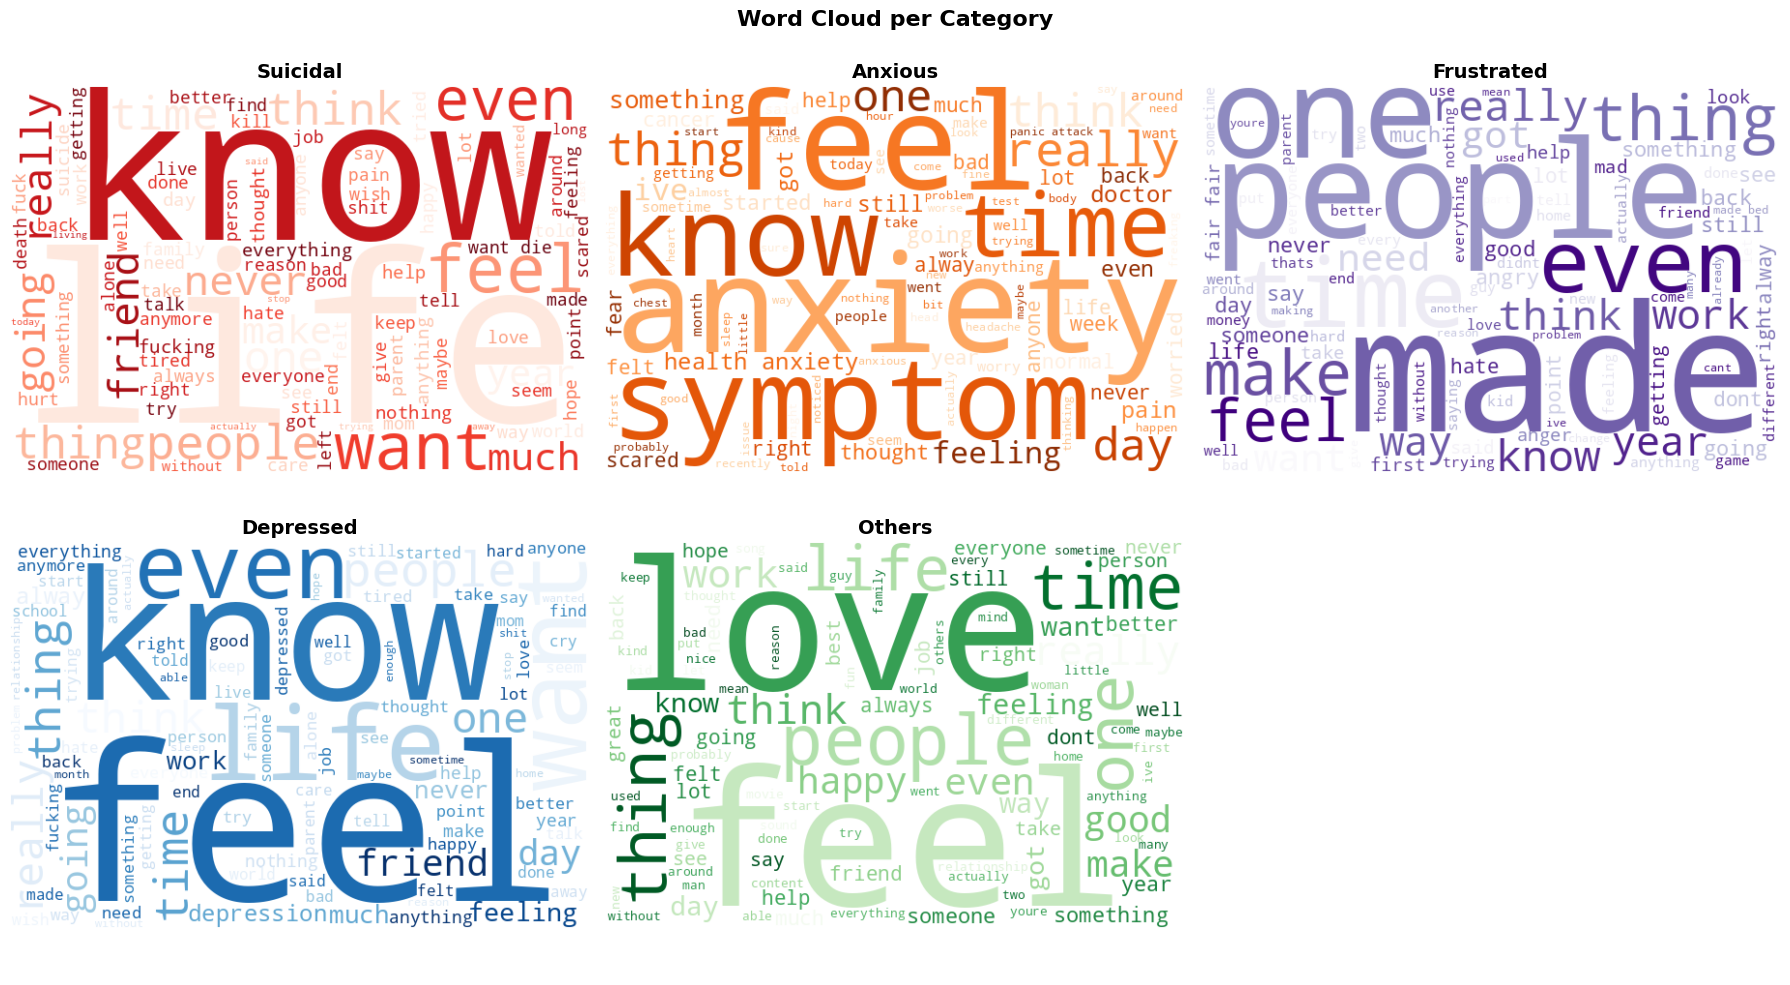

In [25]:
# WORD CLOUD PER CATEGORY AFTER PREPROCESSING

# Define colors per category
category_colors = {
    'Suicidal': 'Reds',
    'Depressed': 'Blues',
    'Anxious': 'Oranges',
    'Frustrated': 'Purples',
    'Others': 'Greens'
}

categories = data['label'].unique()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, category in enumerate(categories):
    # Filter text for each category
    category_text = ' '.join(
        data[data['label'] == category]['clean_text'].values
    )

    # Generate word cloud
    wordcloud = WordCloud(
        width=600,
        height=400,
        background_color='white',
        colormap=category_colors[category],
        max_words=100,
        min_font_size=8
    ).generate(category_text)

    # Plot
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f'{category}',
                      fontsize=14, fontweight='bold')

# Hide last empty subplot
axes[-1].axis('off')

plt.suptitle('Word Cloud per Category',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
# Check vocabulary size with different min_df values
print("Vocabulary size with different min_df values:")
for min_df in [1, 2, 5, 10, 20, 50]:
    cv_test = CountVectorizer(min_df=min_df)
    X_test = cv_test.fit_transform(data['clean_text'])
    print(f"min_df={min_df}: {len(cv_test.vocabulary_)} words")

Vocabulary size with different min_df values:
min_df=1: 26019 words
min_df=2: 12071 words
min_df=5: 6373 words
min_df=10: 4093 words
min_df=20: 2590 words
min_df=50: 1382 words


In [27]:
# Check vocabulary size with different max_df values
print("Vocabulary size with different max_df values:")
for max_df in [0.5, 0.7, 0.8, 0.9, 0.95, 1.0]:
    cv_test = CountVectorizer(max_df=max_df)
    X_test = cv_test.fit_transform(data['clean_text'])
    print(f"max_df={max_df}: {len(cv_test.vocabulary_)} words")

Vocabulary size with different max_df values:
max_df=0.5: 26019 words
max_df=0.7: 26019 words
max_df=0.8: 26019 words
max_df=0.9: 26019 words
max_df=0.95: 26019 words
max_df=1.0: 26019 words


In [28]:
# ENCODE LABELS
le = LabelEncoder()
y = le.fit_transform(data['label'])
print(f"Classes: {le.classes_}")

Classes: ['Anxious' 'Depressed' 'Frustrated' 'Others' 'Suicidal']


In [29]:
# TRAIN TEST SPLIT

train_idx, test_idx = train_test_split(
    range(len(y)),
    test_size=0.2,
    random_state=42,
    stratify=y
)

y_train = y[train_idx]
y_test = y[test_idx]

train_text = data['clean_text'].iloc[train_idx]
test_text = data['clean_text'].iloc[test_idx]

print(f"Training rows: {len(train_idx)}")
print(f"Test rows:     {len(test_idx)}")

Training rows: 8040
Test rows:     2010


In [30]:
# TF-IDF FIT ON TRAINING ONLY
# UNIGRAM (1,1)
tfidf_unigram = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    max_features=10000,
    smooth_idf=True
)
X_train_uni = tfidf_unigram.fit_transform(train_text)
X_test_uni = tfidf_unigram.transform(test_text)
print(f"Unigram (1,1)")
print(f"  Training: {X_train_uni.shape}")
print(f"  Test:     {X_test_uni.shape}")

# UNIGRAM + BIGRAM (1,2)
tfidf_unibigram = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    max_features=15000,
    smooth_idf=True
)
X_train_unibi = tfidf_unibigram.fit_transform(train_text)
X_test_unibi = tfidf_unibigram.transform(test_text)
print(f"\nUniBigram (1,2)")
print(f"  Training: {X_train_unibi.shape}")
print(f"  Test:     {X_test_unibi.shape}")

# UNIGRAM + BIGRAM + TRIGRAM (1,3)
tfidf_unitrigram = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    max_features=20000,
    smooth_idf=True
)
X_train_unitri = tfidf_unitrigram.fit_transform(train_text)
X_test_unitri = tfidf_unitrigram.transform(test_text)
print(f"\nUniTrigram (1,3)")
print(f"  Training: {X_train_unitri.shape}")
print(f"  Test:     {X_test_unitri.shape}")

# Class distribution
print("\nClass distribution in training set:")
for i, category in enumerate(le.classes_):
    print(f"  {category}: {(y_train == i).sum()}")

print("\nClass distribution in test set:")
for i, category in enumerate(le.classes_):
    print(f"  {category}: {(y_test == i).sum()}")

Unigram (1,1)
  Training: (8040, 7966)
  Test:     (2010, 7966)

UniBigram (1,2)
  Training: (8040, 15000)
  Test:     (2010, 15000)

UniTrigram (1,3)
  Training: (8040, 20000)
  Test:     (2010, 20000)

Class distribution in training set:
  Anxious: 1630
  Depressed: 1638
  Frustrated: 1617
  Others: 1419
  Suicidal: 1736

Class distribution in test set:
  Anxious: 408
  Depressed: 409
  Frustrated: 404
  Others: 355
  Suicidal: 434


Data modelling

In [31]:
# MODELS AND HYPERPARAMETERS
models = {
    'Logistic Regression': {
        'model': LogisticRegression(
            random_state=42,
            max_iter=1000,
            class_weight='balanced'
        ),
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['lbfgs', 'saga']
        }
    },
    'Naive Bayes': {
        'model': MultinomialNB(),
        'params': {
            'alpha': [0.1, 0.5, 1.0, 2.0]
        }
    },
    'SVM': {
        'model': LinearSVC(
            random_state=42,
            max_iter=1000,
            class_weight='balanced'
        ),
        'params': {
            'C': [0.1, 1, 10]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(
            random_state=42,
            class_weight='balanced'
        ),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5]
        }
    }
}

# CROSS VALIDATION STRATEGY
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Models defined successfully!")
for name in models.keys():
    print(f"  - {name}")

Models defined successfully!
  - Logistic Regression
  - Naive Bayes
  - SVM
  - Random Forest


In [32]:
# GRID SEARCH + 5-FOLD CV

grid_results = {}

def run_gridsearch(X_train, y_train, feature_name):
    print(f"\n{'='*50}")
    print(f"Feature: {feature_name}")
    print(f"{'='*50}")

    feature_results = {}

    for name, config in models.items():
        print(f"\nTuning {name}...")
        start = time.time()

        grid = GridSearchCV(
            estimator=config['model'],
            param_grid=config['params'],
            cv=cv,
            scoring='accuracy',
            n_jobs=-1,
            verbose=0
        )

        grid.fit(X_train, y_train)
        elapsed = time.time() - start

        print(f"  Best params: {grid.best_params_}")
        print(f"  Best CV Acc: {grid.best_score_:.4f}")
        print(f"  Time:        {elapsed:.1f}s")

        feature_results[name] = grid

    return feature_results

# RUN GRID SEARCH
grid_results['Unigram'] = run_gridsearch(
    X_train_uni, y_train, 'Unigram (1,1)'
)
grid_results['UniBigram'] = run_gridsearch(
    X_train_unibi, y_train, 'Unigram + Bigram (1,2)'
)
grid_results['UniTrigram'] = run_gridsearch(
    X_train_unitri, y_train, 'Unigram + Bigram + Trigram (1,3)'
)

print("\n All models trained and tuned successfully!")


Feature: Unigram (1,1)

Tuning Logistic Regression...
  Best params: {'C': 1, 'solver': 'saga'}
  Best CV Acc: 0.7679
  Time:        17.3s

Tuning Naive Bayes...
  Best params: {'alpha': 0.5}
  Best CV Acc: 0.6856
  Time:        0.4s

Tuning SVM...
  Best params: {'C': 0.1}
  Best CV Acc: 0.7690
  Time:        3.9s

Tuning Random Forest...
  Best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
  Best CV Acc: 0.7438
  Time:        393.1s

Feature: Unigram + Bigram (1,2)

Tuning Logistic Regression...
  Best params: {'C': 1, 'solver': 'lbfgs'}
  Best CV Acc: 0.7706
  Time:        19.5s

Tuning Naive Bayes...
  Best params: {'alpha': 0.1}
  Best CV Acc: 0.7020
  Time:        0.3s

Tuning SVM...
  Best params: {'C': 0.1}
  Best CV Acc: 0.7741
  Time:        4.1s

Tuning Random Forest...
  Best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
  Best CV Acc: 0.7405
  Time:        471.9s

Feature: Unigram + Bigram + Trigram (1,3)

Tuning Logis

In [33]:
# EVALUATE — TEST SET + 5-FOLD CV

def run_models(X_train, X_test, y_train, y_test, feature_name):
    print(f"\n{'='*60}")
    print(f"RESULTS — {feature_name}")
    print(f"{'='*60}")

    results_list = []

    for name in models.keys():
        # Get best estimator from grid search
        model = grid_results[feature_name][name].best_estimator_

        # Predict on test set
        y_pred = model.predict(X_test)

        # Test set metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

        # 5-Fold CV accuracy on training set
        cv_scores = cross_val_score(
            model, X_train, y_train,
            cv=kf, scoring='accuracy'
        )

        results_list.append({
            'Model': name,
            'Accuracy': round(acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'F1 Score': round(f1, 4),
            'CV Accuracy': round(np.mean(cv_scores), 4)
        })

    df = pd.DataFrame(results_list)
    print(df.to_string(index=False))
    return df

# RUN FOR ALL THREE FEATURE SETS
df_uni = run_models(X_train_uni, X_test_uni,
                    y_train, y_test, 'Unigram')

df_unibi = run_models(X_train_unibi, X_test_unibi,
                      y_train, y_test, 'UniBigram')

df_unitri = run_models(X_train_unitri, X_test_unitri,
                       y_train, y_test, 'UniTrigram')


RESULTS — Unigram
              Model  Accuracy  Precision  Recall  F1 Score  CV Accuracy
Logistic Regression    0.7945     0.7948  0.7970    0.7935       0.7653
        Naive Bayes    0.7090     0.7296  0.7006    0.7010       0.6808
                SVM    0.8005     0.7995  0.8026    0.7971       0.7713
      Random Forest    0.7741     0.7795  0.7765    0.7648       0.7409

RESULTS — UniBigram
              Model  Accuracy  Precision  Recall  F1 Score  CV Accuracy
Logistic Regression    0.7955     0.7959  0.7979    0.7949       0.7703
        Naive Bayes    0.7214     0.7215  0.7165    0.7166       0.6981
                SVM    0.8050     0.8044  0.8068    0.8011       0.7715
      Random Forest    0.7791     0.7855  0.7819    0.7721       0.7310

RESULTS — UniTrigram
              Model  Accuracy  Precision  Recall  F1 Score  CV Accuracy
Logistic Regression    0.7970     0.7979  0.7994    0.7966       0.7684
        Naive Bayes    0.7189     0.7202  0.7140    0.7140       0.6979
  

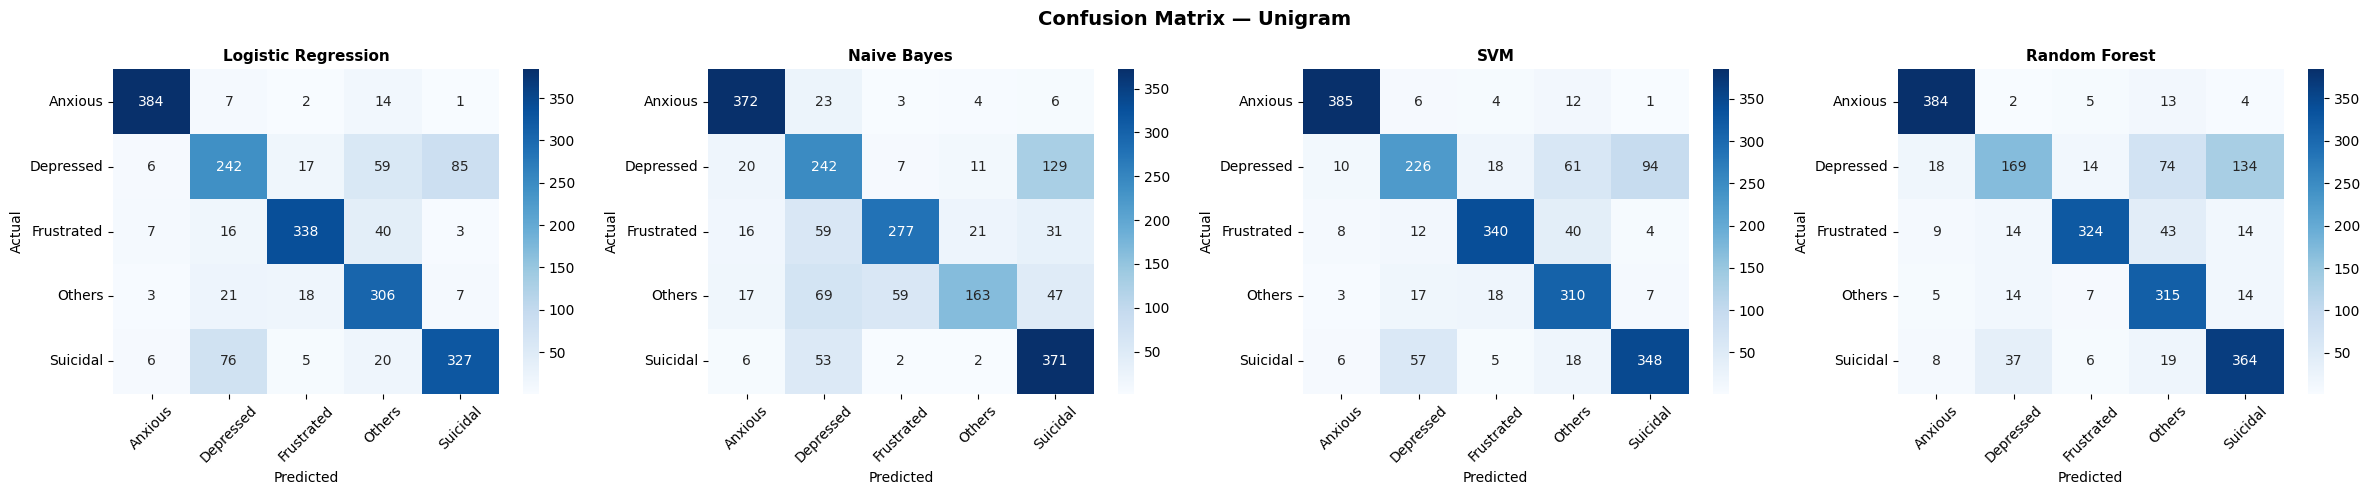

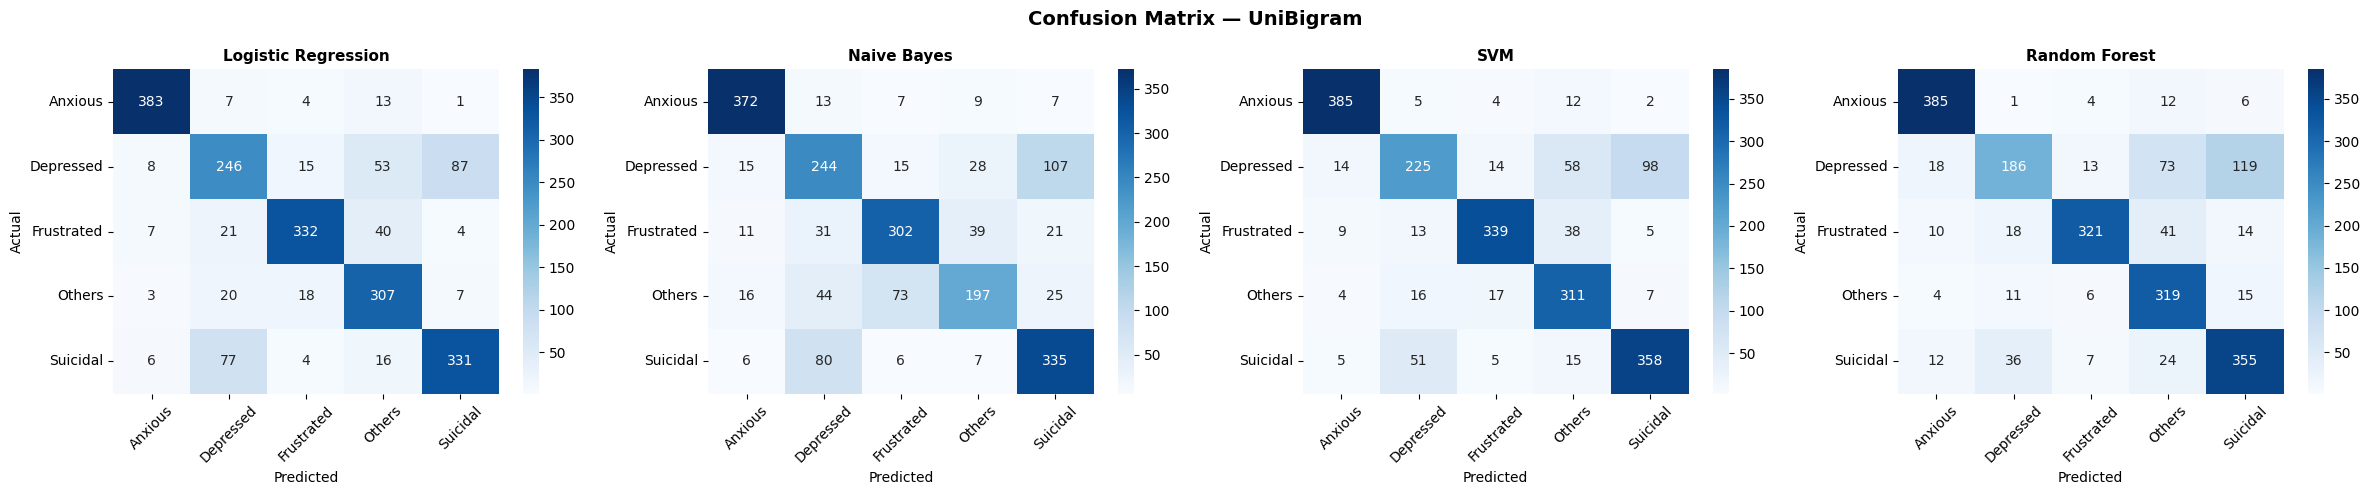

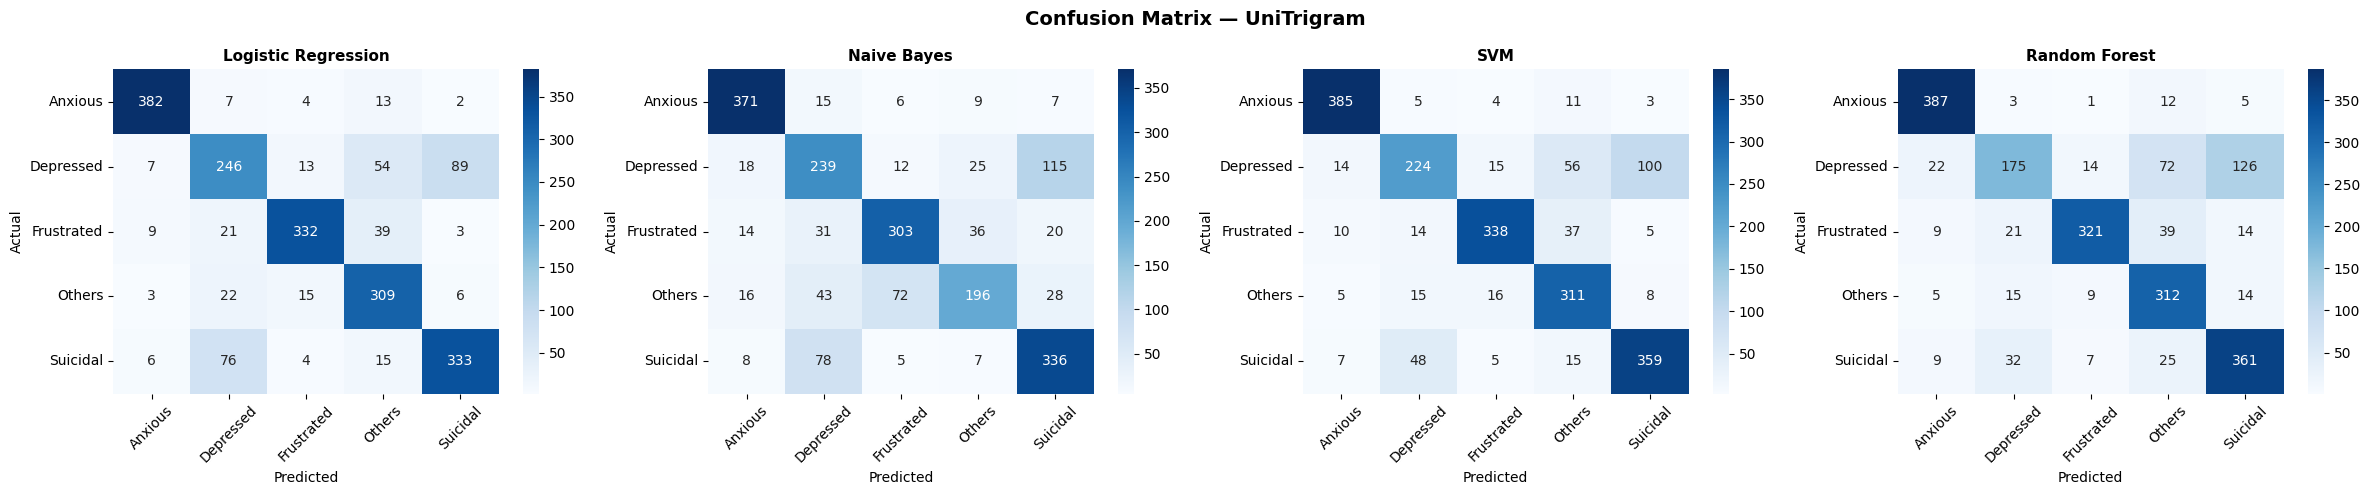

In [34]:
# CONFUSION MATRIX — ALL MODELS

labels = le.classes_

def plot_confusion_matrices(feature_name, X_test):
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))

    for i, (model_name, grid) in enumerate(grid_results[feature_name].items()):
        y_pred = grid.best_estimator_.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=labels,
            yticklabels=labels,
            ax=axes[i]
        )
        axes[i].set_title(f'{model_name}',
                          fontsize=11, fontweight='bold')
        axes[i].set_xlabel('Predicted')
        axes[i].set_ylabel('Actual')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].tick_params(axis='y', rotation=0)

    plt.suptitle(f'Confusion Matrix — {feature_name}',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


# PLOT FOR ALL THREE FEATURE SETS
plot_confusion_matrices('Unigram', X_test_uni)
plot_confusion_matrices('UniBigram', X_test_unibi)
plot_confusion_matrices('UniTrigram', X_test_unitri)

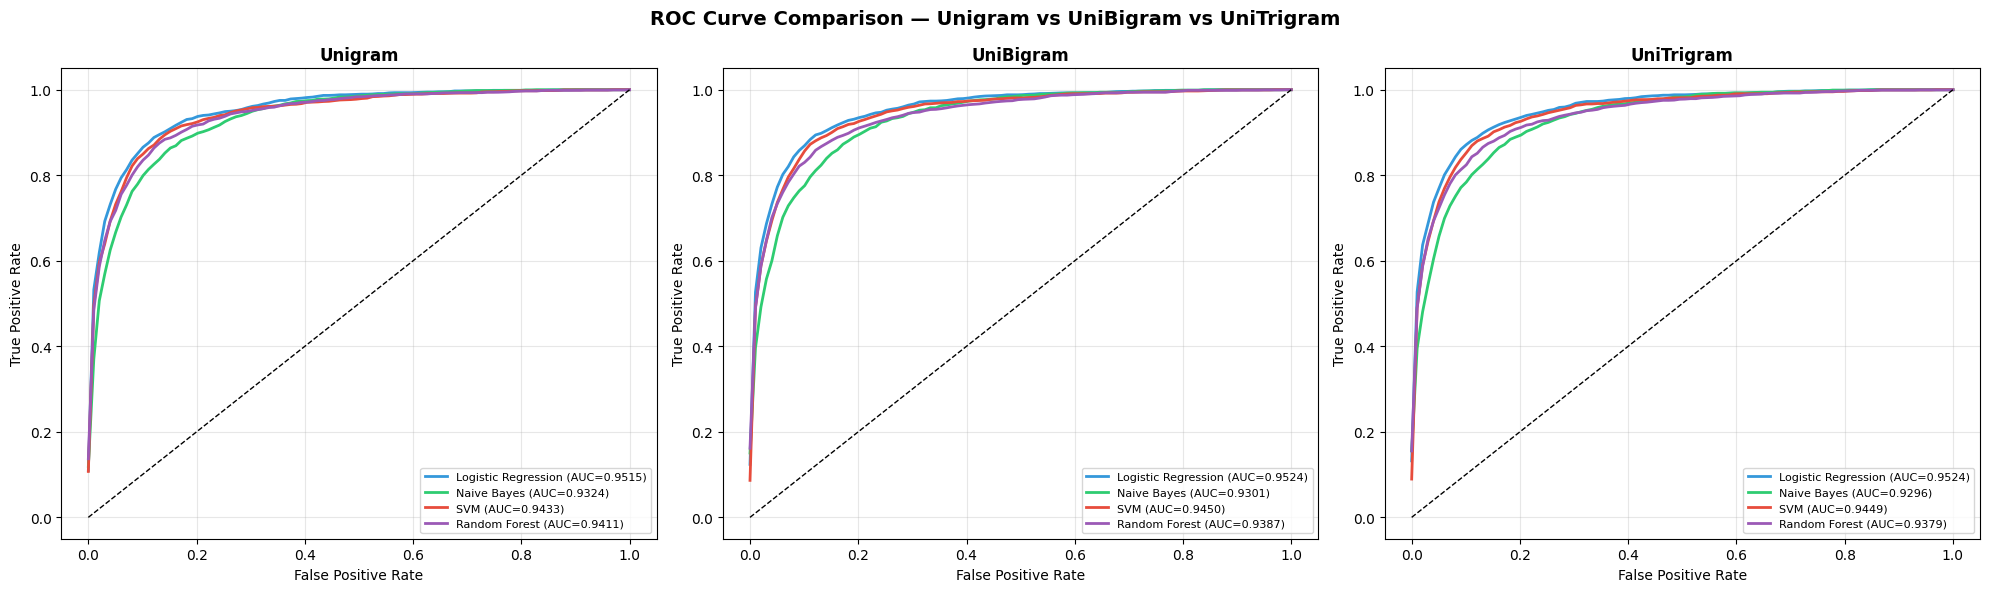

In [35]:
# AUC-ROC — ALL MODELS COMBINED

from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Binarize y_test
y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))

# Colors per model
model_colors = {
    'Logistic Regression': '#3498DB',
    'Naive Bayes': '#2ECC71',
    'SVM': '#E74C3C',
    'Random Forest': '#9B59B6'
}

# Test sets — all three
test_sets = {
    'Unigram': X_test_uni,
    'UniBigram': X_test_unibi,
    'UniTrigram': X_test_unitri
}

# PLOT — ONE CHART PER FEATURE SET
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

auc_results = []

for ax, (feature_name, X_test) in zip(axes, test_sets.items()):
    for model_name, grid in grid_results[feature_name].items():

        # Get scores
        if hasattr(grid.best_estimator_, 'predict_proba'):
            y_score = grid.best_estimator_.predict_proba(X_test)
        else:
            y_score = grid.best_estimator_.decision_function(X_test)

        # Macro AUC
        auc_macro = roc_auc_score(
            y_test_bin, y_score,
            multi_class='ovr',
            average='macro'
        )

        # Macro ROC curve
        fpr_all = []
        tpr_all = []
        for i in range(len(le.classes_)):
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
            fpr_all.append(fpr)
            tpr_all.append(tpr)

        # Interpolate for macro average
        mean_fpr = np.linspace(0, 1, 100)
        mean_tpr = np.mean([np.interp(mean_fpr, f, t)
                            for f, t in zip(fpr_all, tpr_all)], axis=0)

        ax.plot(mean_fpr, mean_tpr,
                color=model_colors[model_name],
                linewidth=2,
                label=f'{model_name} (AUC={auc_macro:.4f})')

        auc_results.append({
            'Feature': feature_name,
            'Model': model_name,
            'AUC-ROC': round(auc_macro, 4)
        })

    # Diagonal
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{feature_name}',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('ROC Curve Comparison — Unigram vs UniBigram vs UniTrigram',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [36]:
# AUC SUMMARY TABLE
auc_df = pd.DataFrame(auc_results)
print("="*45)
print("AUC-ROC SUMMARY TABLE")
print("="*45)
print(auc_df.to_string(index=False))

AUC-ROC SUMMARY TABLE
   Feature               Model  AUC-ROC
   Unigram Logistic Regression   0.9515
   Unigram         Naive Bayes   0.9324
   Unigram                 SVM   0.9433
   Unigram       Random Forest   0.9411
 UniBigram Logistic Regression   0.9524
 UniBigram         Naive Bayes   0.9301
 UniBigram                 SVM   0.9450
 UniBigram       Random Forest   0.9387
UniTrigram Logistic Regression   0.9524
UniTrigram         Naive Bayes   0.9296
UniTrigram                 SVM   0.9449
UniTrigram       Random Forest   0.9379


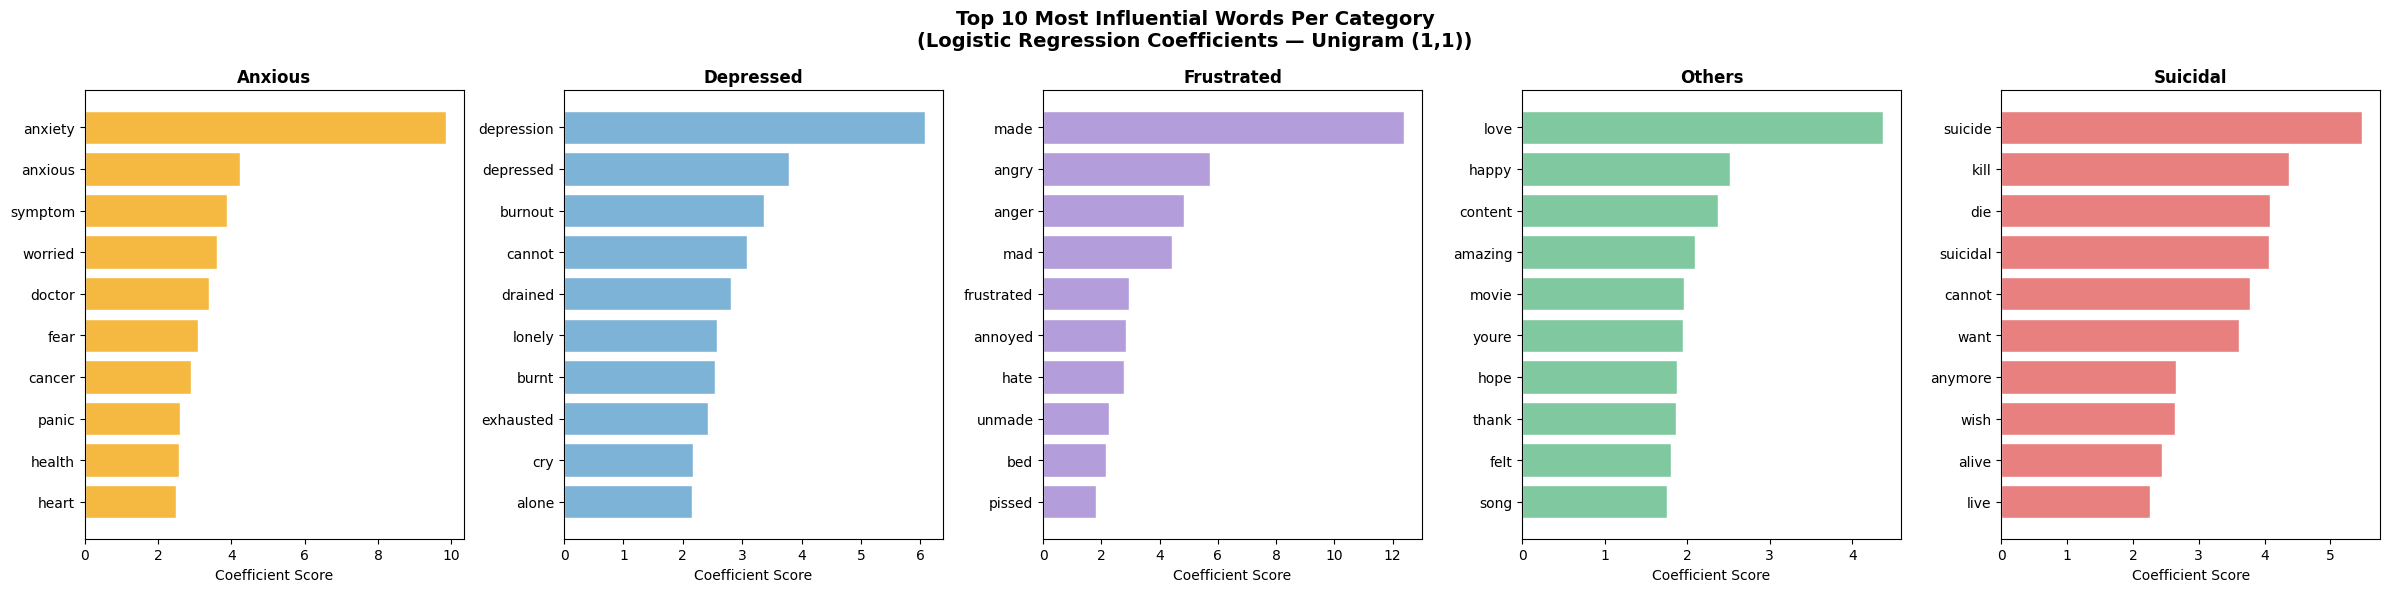

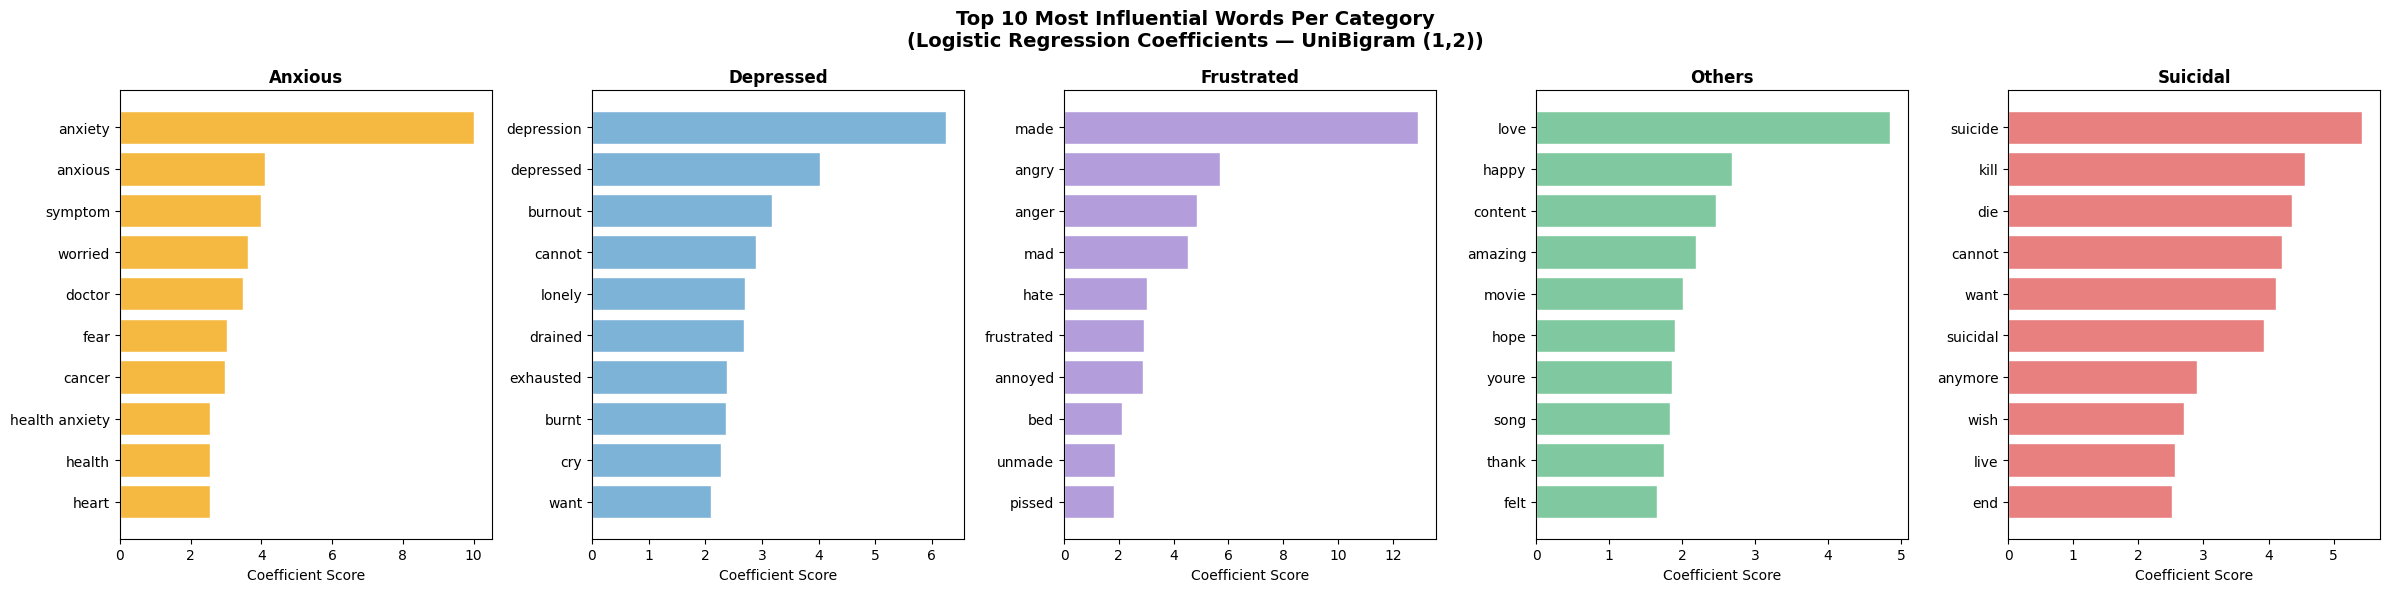

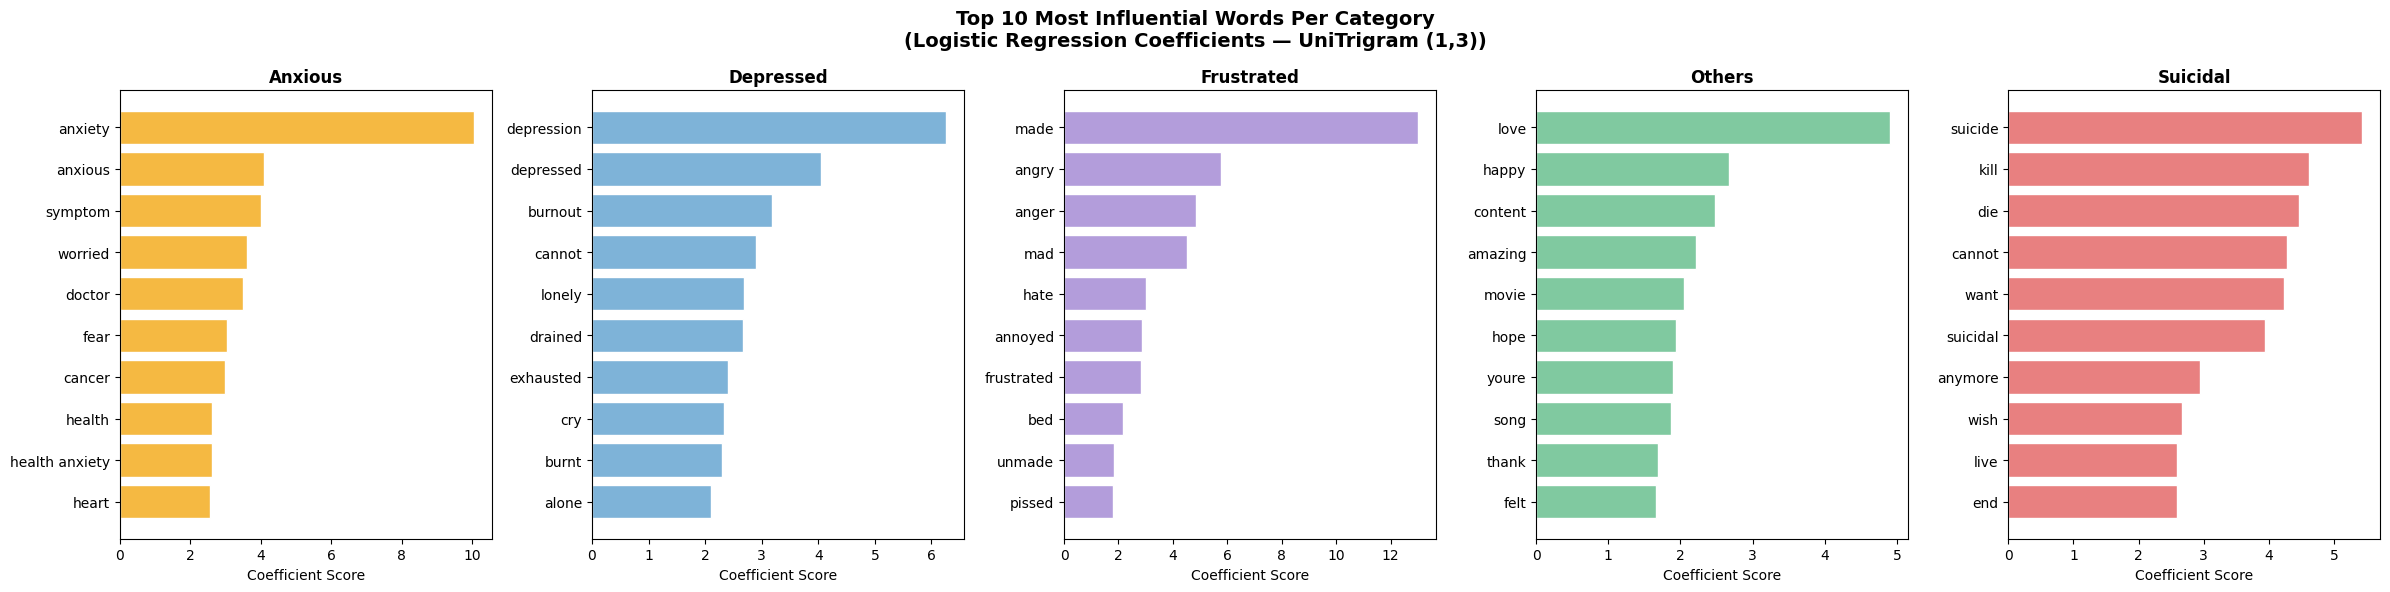

In [37]:
# LOGISTIC REGRESSION COEFFICIENTS
# TOP 10 WORDS PER CATEGORY — ALL FEATURE SETS

# Soft color palette
category_colors = {
    'Suicidal': '#E88080',
    'Depressed': '#7EB3D8',
    'Anxious': '#F5B942',
    'Frustrated': '#B39DDB',
    'Others': '#80C9A0'
}

# Feature sets
feature_sets = {
    'Unigram (1,1)': (grid_results['Unigram'], tfidf_unigram),
    'UniBigram (1,2)': (grid_results['UniBigram'], tfidf_unibigram),
    'UniTrigram (1,3)': (grid_results['UniTrigram'], tfidf_unitrigram)
}

categories = le.classes_

for feature_name, (feature_result, vectorizer) in feature_sets.items():

    lr_model = feature_result['Logistic Regression'].best_estimator_
    feature_names = np.array(vectorizer.get_feature_names_out())

    fig, axes = plt.subplots(1, 5, figsize=(24, 6))

    for i, (category, ax) in enumerate(zip(categories, axes)):
        coef = lr_model.coef_[i]
        top_idx = np.argsort(coef)[-10:][::-1]
        top_words = feature_names[top_idx]
        top_scores = coef[top_idx]

        ax.barh(top_words[::-1], top_scores[::-1],
                color=category_colors[category],
                edgecolor='white')
        ax.set_title(f'{category}',
                     fontsize=12, fontweight='bold')
        ax.set_xlabel('Coefficient Score')
        ax.set_ylabel('')

    plt.suptitle(f'Top 10 Most Influential Words Per Category\n(Logistic Regression Coefficients — {feature_name})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

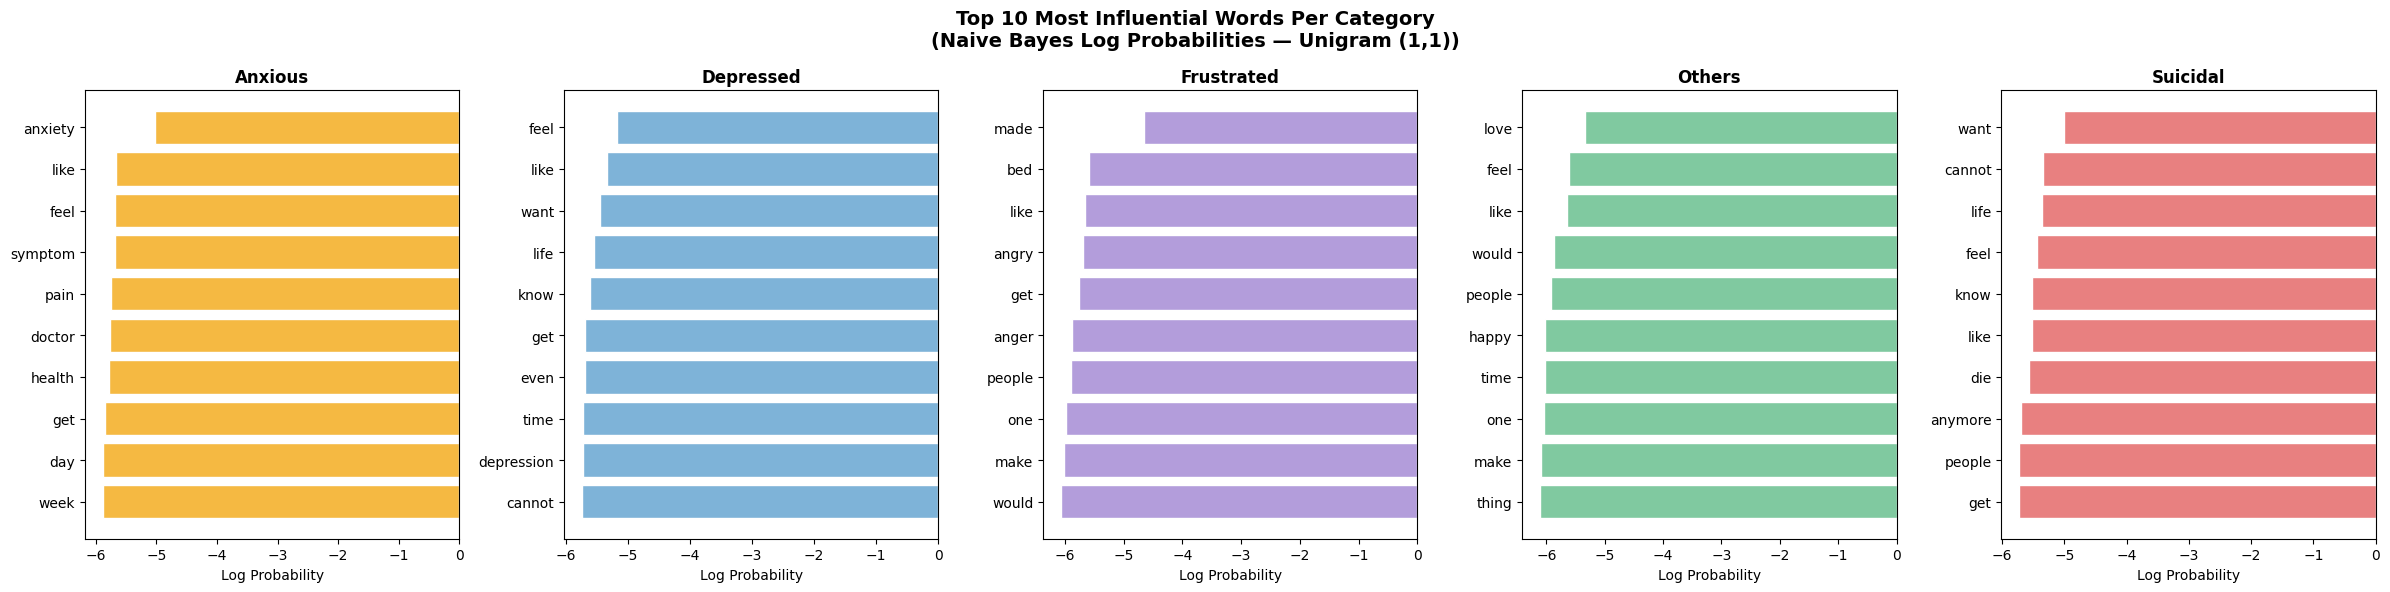

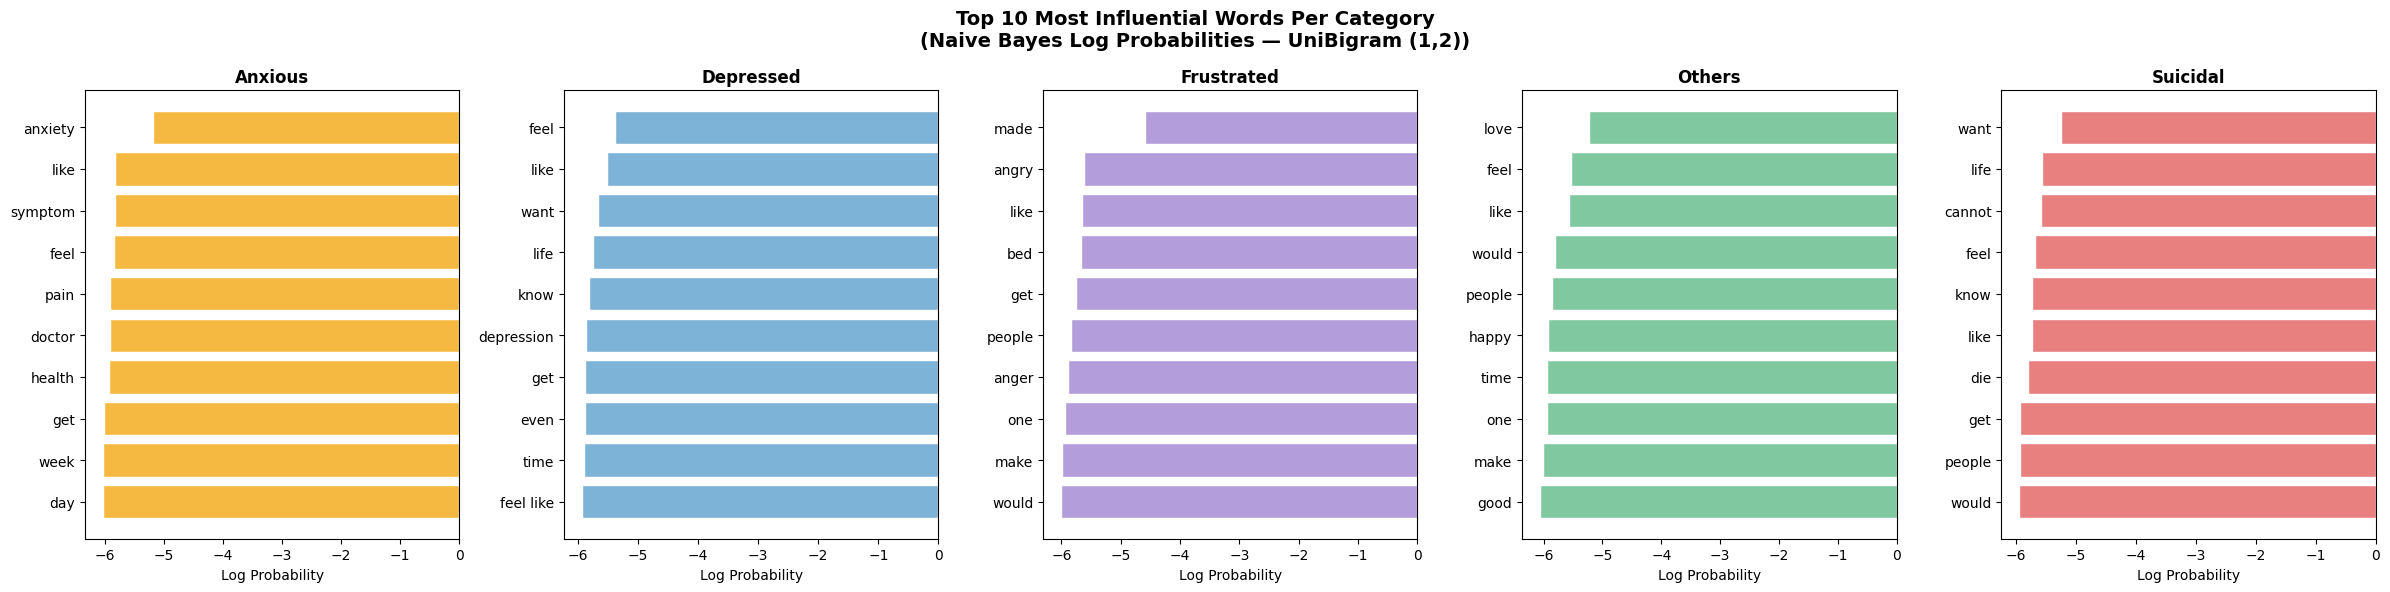

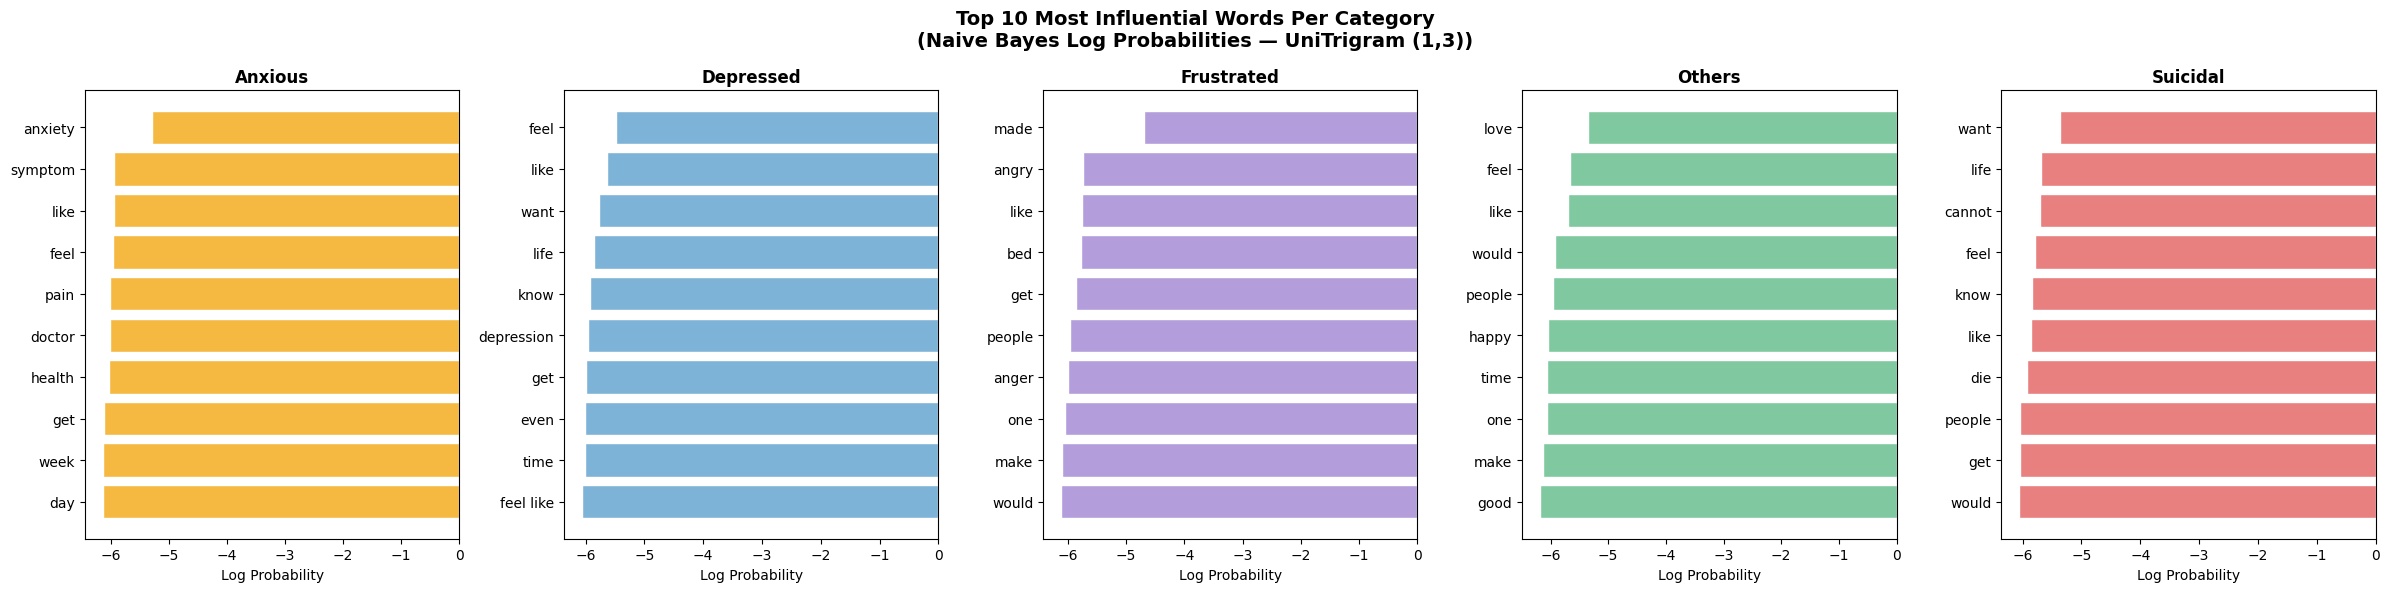

In [38]:
# NAIVE BAYES LOG PROBABILITIES
# TOP 10 WORDS PER CATEGORY — ALL FEATURE SETS

# Soft color palette
category_colors = {
    'Suicidal': '#E88080',
    'Depressed': '#7EB3D8',
    'Anxious': '#F5B942',
    'Frustrated': '#B39DDB',
    'Others': '#80C9A0'
}

# Feature sets
feature_sets = {
    'Unigram (1,1)': (grid_results['Unigram'], tfidf_unigram),
    'UniBigram (1,2)': (grid_results['UniBigram'], tfidf_unibigram),
    'UniTrigram (1,3)': (grid_results['UniTrigram'], tfidf_unitrigram)
}

categories = le.classes_

for feature_name, (feature_result, vectorizer) in feature_sets.items():

    nb_model = feature_result['Naive Bayes'].best_estimator_
    feature_names = np.array(vectorizer.get_feature_names_out())

    fig, axes = plt.subplots(1, 5, figsize=(24, 6))

    for i, (category, ax) in enumerate(zip(categories, axes)):
        # Get log probabilities for this category
        log_prob = nb_model.feature_log_prob_[i]

        # Top 10 highest log probabilities
        top_idx = np.argsort(log_prob)[-10:][::-1]
        top_words = feature_names[top_idx]
        top_scores = log_prob[top_idx]

        ax.barh(top_words[::-1], top_scores[::-1],
                color=category_colors[category],
                edgecolor='white')
        ax.set_title(f'{category}',
                     fontsize=12, fontweight='bold')
        ax.set_xlabel('Log Probability')
        ax.set_ylabel('')

    plt.suptitle(f'Top 10 Most Influential Words Per Category\n(Naive Bayes Log Probabilities — {feature_name})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [39]:
# SHAP — SVM AND RANDOM FOREST
!pip install shap -q
import shap
# Feature sets
feature_sets = {
    'Unigram (1,1)': (grid_results['Unigram'], tfidf_unigram),
    'UniBigram (1,2)': (grid_results['UniBigram'], tfidf_unibigram),
    'UniTrigram (1,3)': (grid_results['UniTrigram'], tfidf_unitrigram)
}

categories = le.classes_

# Soft color palette
category_colors = {
    'Suicidal': '#E88080',
    'Depressed': '#7EB3D8',
    'Anxious': '#F5B942',
    'Frustrated': '#B39DDB',
    'Others': '#80C9A0'
}


Unigram (1,1) — SHAP values type: <class 'numpy.ndarray'>
Shape: (100, 7966, 5)


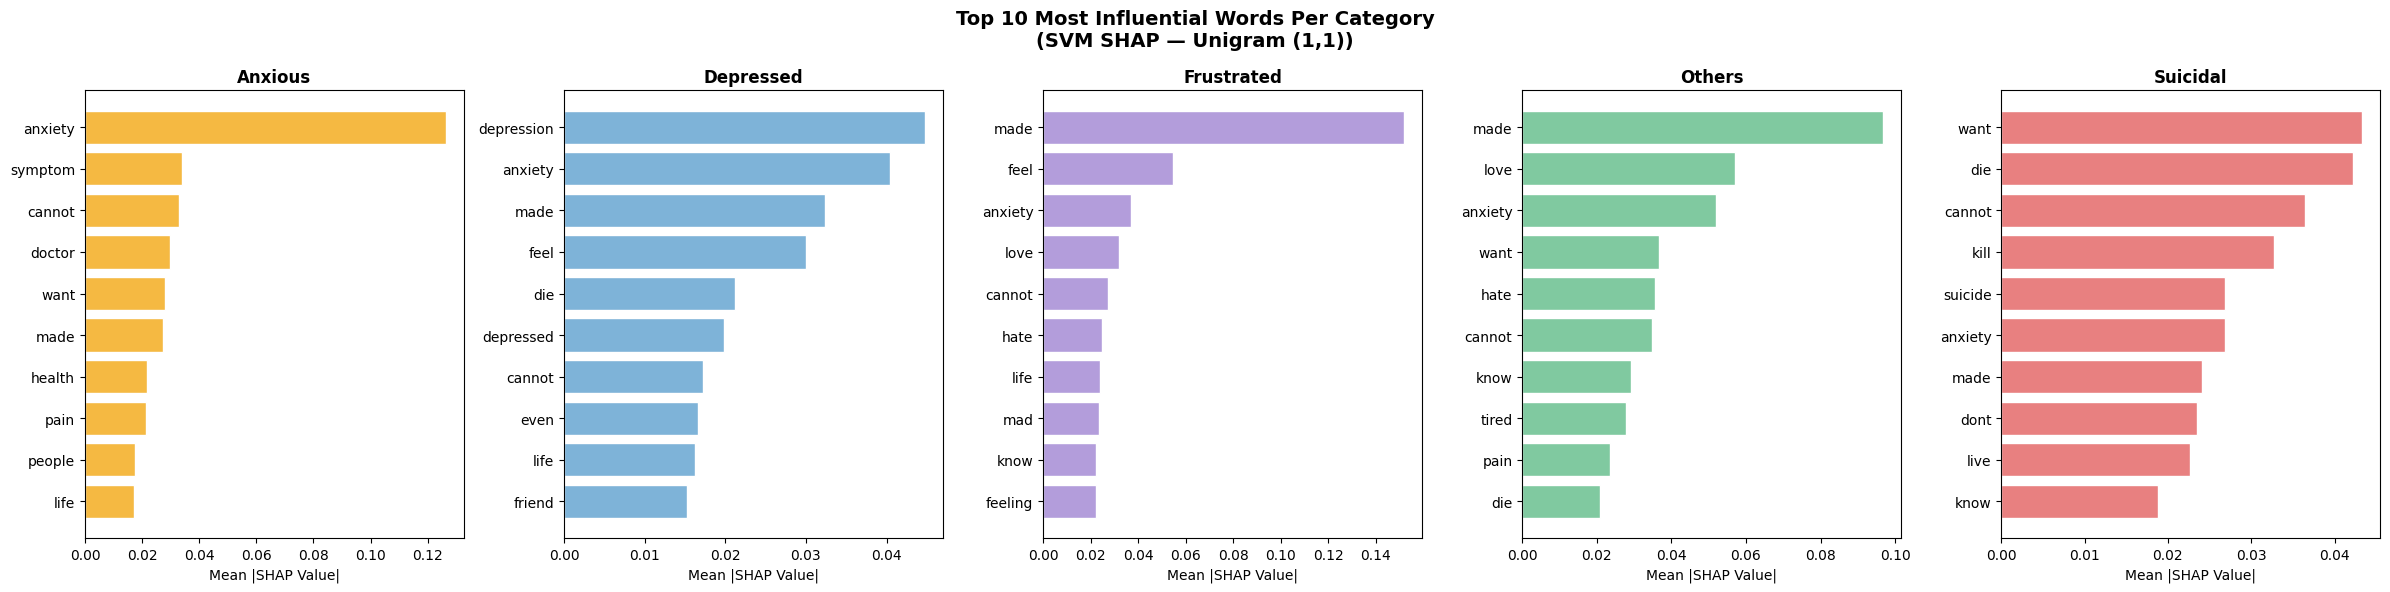


UniBigram (1,2) — SHAP values type: <class 'numpy.ndarray'>
Shape: (100, 15000, 5)


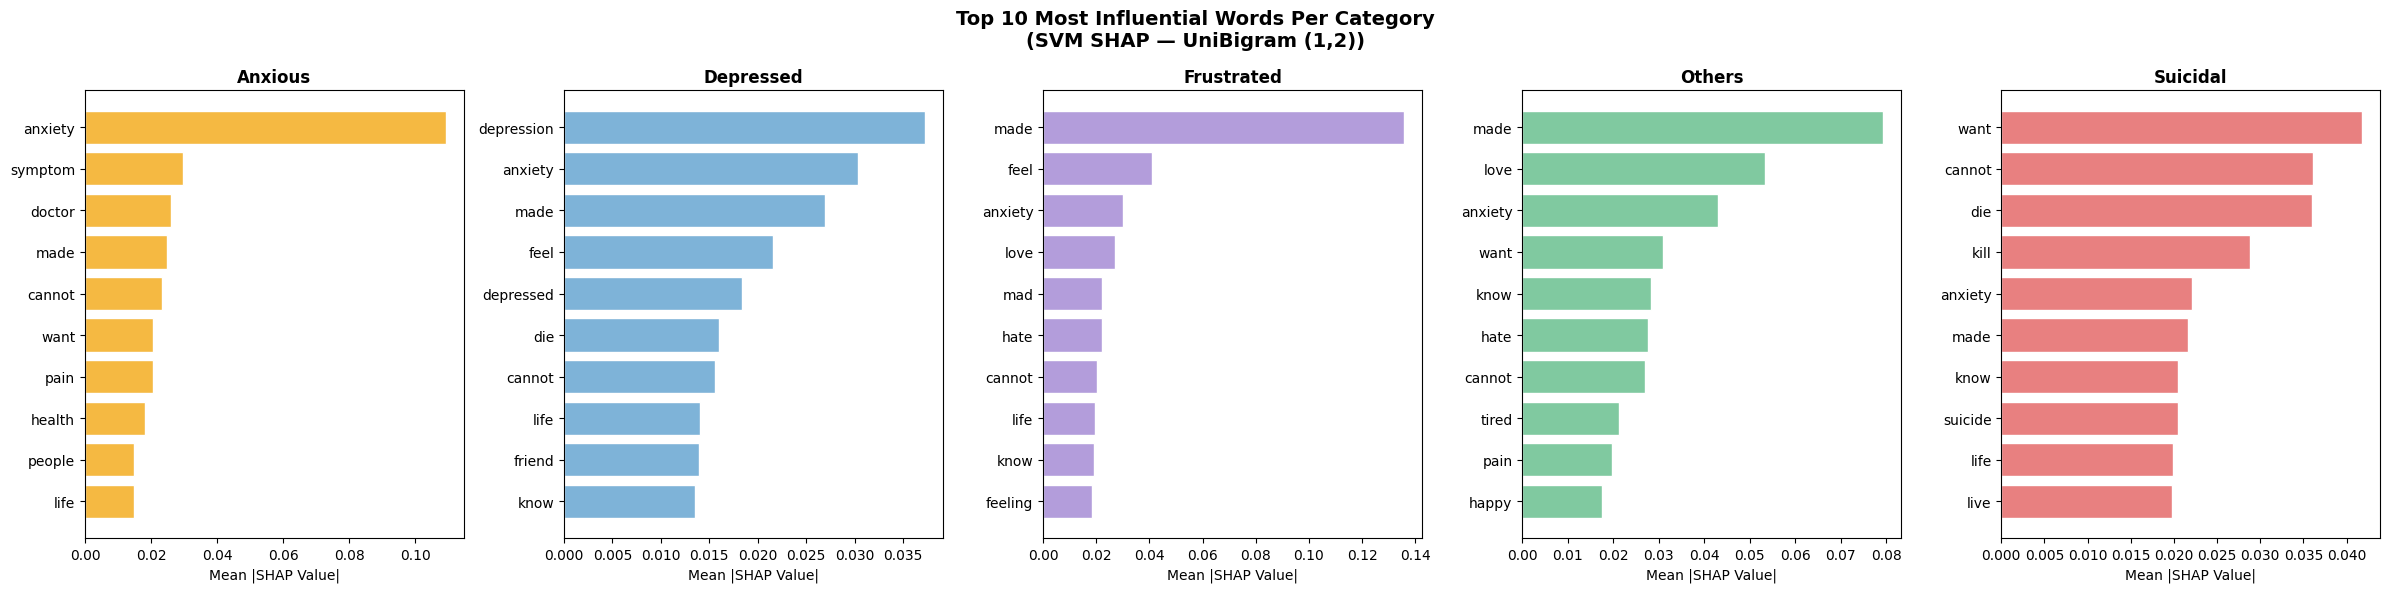


UniTrigram (1,3) — SHAP values type: <class 'numpy.ndarray'>
Shape: (100, 20000, 5)


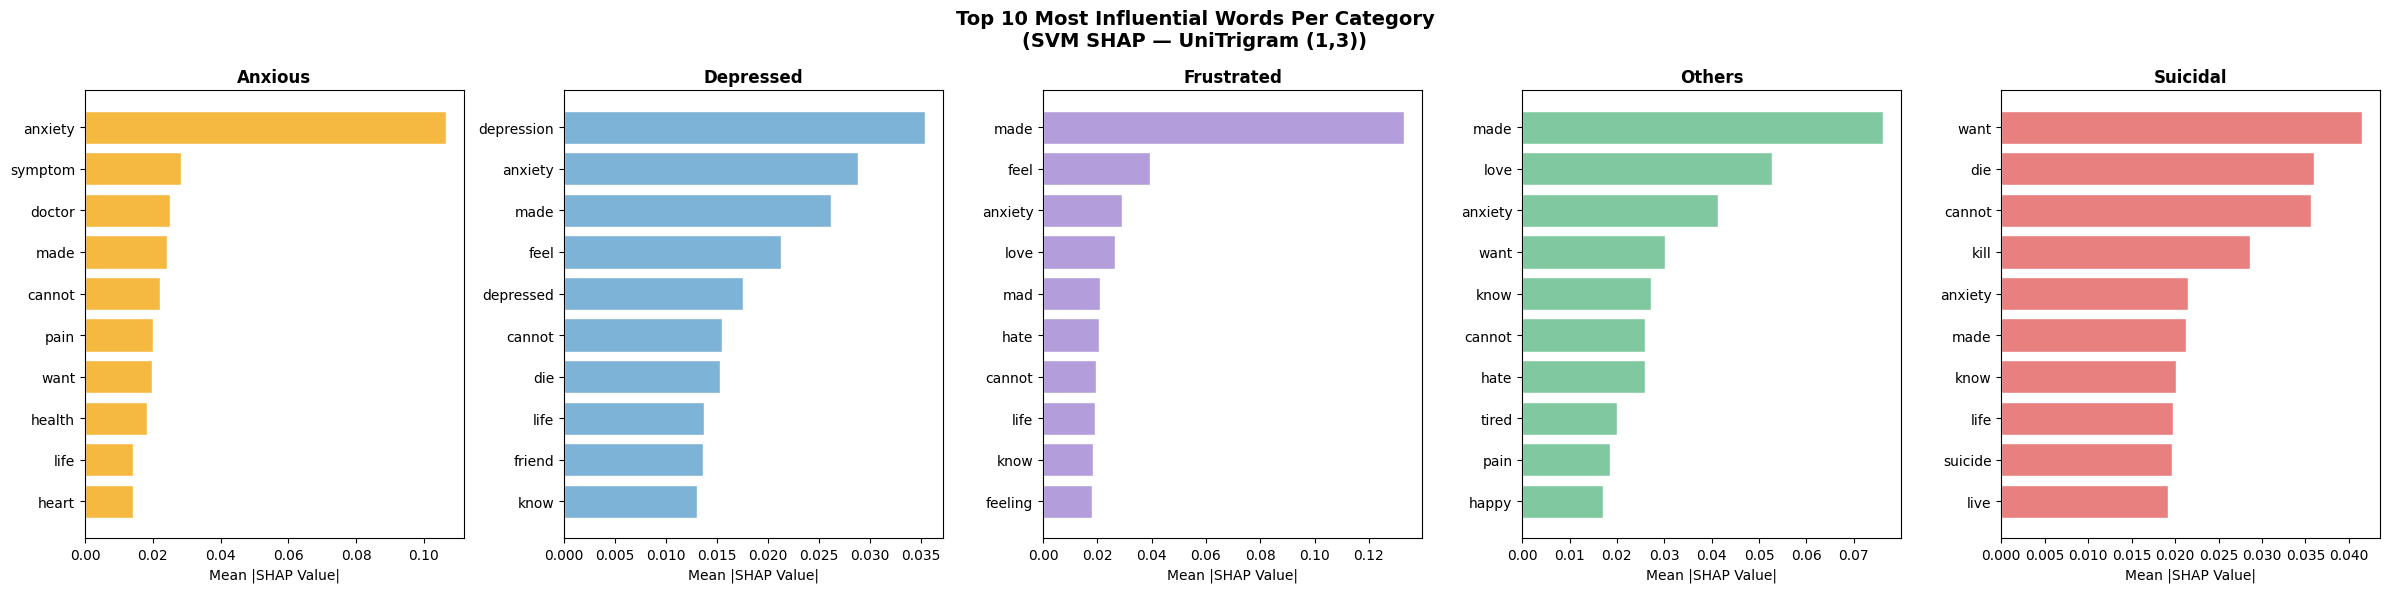

In [40]:
# SHAP FOR SVM (LinearSVC)

feature_sets = {
    'Unigram (1,1)': (grid_results['Unigram'], tfidf_unigram, X_test_uni, X_train_uni),
    'UniBigram (1,2)': (grid_results['UniBigram'], tfidf_unibigram, X_test_unibi, X_train_unibi),
    'UniTrigram (1,3)': (grid_results['UniTrigram'], tfidf_unitrigram, X_test_unitri, X_train_unitri)
}

categories = le.classes_

category_colors = {
    'Suicidal': '#E88080',
    'Depressed': '#7EB3D8',
    'Anxious': '#F5B942',
    'Frustrated': '#B39DDB',
    'Others': '#80C9A0'
}

for feature_name, (feature_result, vectorizer, X_test, X_train) in feature_sets.items():

    svm_model = feature_result['SVM'].best_estimator_
    feature_names = np.array(vectorizer.get_feature_names_out())

    # Convert to dense for SHAP
    X_train_dense = X_train[:100].toarray()
    X_test_dense = X_test[:100].toarray()

    # LinearExplainer for LinearSVC
    explainer = shap.LinearExplainer(
        svm_model,
        X_train_dense
    )

    shap_values = explainer.shap_values(X_test_dense)

    # shap_values is (n_samples, n_features, n_classes)
    # or list of arrays
    print(f"\n{feature_name} — SHAP values type: {type(shap_values)}")
    if isinstance(shap_values, list):
        print(f"Number of classes: {len(shap_values)}")
    else:
        print(f"Shape: {np.array(shap_values).shape}")

    # Handle different output formats
    if isinstance(shap_values, list):
        shap_per_class = shap_values
    elif len(np.array(shap_values).shape) == 3:
        shap_per_class = [shap_values[:, :, i]
                          for i in range(len(categories))]
    else:
        shap_per_class = [shap_values]

    fig, axes = plt.subplots(1, 5, figsize=(24, 6))

    for i, (category, ax) in enumerate(zip(categories, axes)):
        shap_mean = np.abs(shap_per_class[i]).mean(axis=0)
        top_idx = np.argsort(shap_mean)[-10:][::-1]
        top_words = feature_names[top_idx]
        top_scores = shap_mean[top_idx]

        ax.barh(top_words[::-1], top_scores[::-1],
                color=category_colors[category],
                edgecolor='white')
        ax.set_title(f'{category}',
                     fontsize=12, fontweight='bold')
        ax.set_xlabel('Mean |SHAP Value|')
        ax.set_ylabel('')

    plt.suptitle(f'Top 10 Most Influential Words Per Category\n(SVM SHAP — {feature_name})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()